<a href="https://colab.research.google.com/github/ankitaguptacs24-ai/BIS/blob/main/CuckooSearch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Optimal Thresholds: [ 86 170]
Best Fitness Value: 39777280.0
MSE: 1820.61
PSNR: 15.53 dB
Original Image:


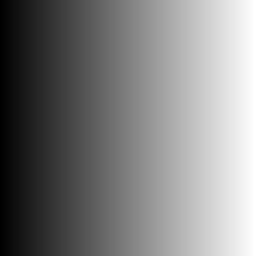

Segmented Image:


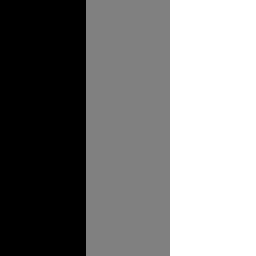

In [3]:
import numpy as np
import cv2
from google.colab.patches import cv2_imshow

# Read the grayscale image
image = cv2.imread("input.jpg", cv2.IMREAD_GRAYSCALE)

# Check whether the image was loaded
if image is None:
    print("Image 'input.jpg' not found! Generating a synthetic gradient image for demonstration...")
    # Generate a dummy gradient image so the script doesn't crash
    image = np.linspace(0, 255, 10000).reshape(100, 100).astype(np.uint8)

# Number of threshold levels
num_thresholds = 2

# Cuckoo Search parameters
n_nests = 15
iterations = 50
pa = 0.25

# Generate random threshold values
def create_solution():
    thresholds = np.random.randint(1, 255, num_thresholds)
    return np.sort(thresholds)

# Apply multilevel thresholding
def segment_image(image, thresholds):
    segmented = np.zeros_like(image)

    if len(thresholds) == 2:
        segmented[image < thresholds[0]] = 0
        segmented[
            (image >= thresholds[0]) &
            (image < thresholds[1])
        ] = 128
        segmented[image >= thresholds[1]] = 255

    return segmented

# Fitness function using image variance
def fitness(image, thresholds):
    segmented = segment_image(image, thresholds)

    score = 0

    for value in [0, 128, 255]:
        pixels = image[segmented == value]

        if len(pixels) > 0:
            score += len(pixels) * np.var(pixels)

    # Lower variance gives better segmentation
    return score

# Levy flight for generating new solutions
def levy_flight():
    step = np.random.normal(0, 1, num_thresholds)
    return step * 10

# Initialize nests
nests = np.array([create_solution() for _ in range(n_nests)])

# Calculate fitness of all nests
fitness_values = np.array([
    fitness(image, nest) for nest in nests
])

# Find the best solution
best_index = np.argmin(fitness_values)
best_solution = nests[best_index].copy()
best_fitness = fitness_values[best_index]

# Main Cuckoo Search loop
for iteration in range(iterations):

    for i in range(n_nests):

        # Generate a new solution using Levy flight
        new_solution = nests[i] + levy_flight()

        # Keep threshold values within valid range
        new_solution = np.clip(new_solution, 1, 254)
        new_solution = np.sort(new_solution.astype(int))

        new_fitness = fitness(image, new_solution)

        # Replace the nest if the new solution is better
        if new_fitness < fitness_values[i]:
            nests[i] = new_solution
            fitness_values[i] = new_fitness

        # Update global best solution
        if new_fitness < best_fitness:
            best_solution = new_solution.copy()
            best_fitness = new_fitness

    # Replace some nests with new random solutions
    for i in range(n_nests):
        if np.random.rand() < pa:
            nests[i] = create_solution()
            fitness_values[i] = fitness(image, nests[i])

# Segment the image using the best thresholds
segmented_image = segment_image(image, best_solution)

# Calculate MSE
mse = np.mean(
    (image.astype(float) - segmented_image.astype(float)) ** 2
)

# Calculate PSNR
if mse == 0:
    psnr = float("inf")
else:
    psnr = 10 * np.log10((255 ** 2) / mse)

# Display results
print("Optimal Thresholds:", best_solution)
print("Best Fitness Value:", round(best_fitness, 2))
print("MSE:", round(mse, 2))
print("PSNR:", round(psnr, 2), "dB")

# Save segmented image
cv2.imwrite("segmented_output.jpg", segmented_image)

# Display images using Colab's cv2_imshow
print("Original Image:")
cv2_imshow(image)
print("Segmented Image:")
cv2_imshow(segmented_image)

In [2]:
import numpy as np
import cv2

# Create a grayscale gradient image
image = np.tile(
    np.linspace(0, 255, 256, dtype=np.uint8),
    (256, 1)
)

# Save the image
cv2.imwrite("input.jpg", image)

print("input.jpg created successfully!")

input.jpg created successfully!
